# Hate Crime Trends in New York City (2019–2024)
**CIS 2300 Group Project** · Dooyeon Jeong, Chengxi Luo, Elmer Rodriguez, Khawar Siddiqui

**Question:** How have hate crimes in NYC changed from 2019 to 2024, where do they happen, and which groups are targeted most?

**Data**
- NYPD Hate Crimes dataset, NYC Open Data (`bqiq-cu78`): one row per confirmed hate crime complaint
- NY State Division of Criminal Justice Services (DCJS): hate crimes by county, 2010–2022, and the 2023 regional update
- FBI Crime Data Explorer, NIBRS hate crime file: offender race and location type
- U.S. Department of Justice hate crime statistics for New York State
- 2020 U.S. Census borough populations, for per-resident rates

**Revised version.** It adds a per-resident comparison by borough and a location-type analysis, uses cross-platform file paths, and produces every chart from code.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import requests

DATA_DIR = "data"
pd.set_option("display.width", 120)
plt.rcParams["figure.dpi"] = 110

## 1. Load and clean the NYPD hate crime data

In [2]:
NYPD_FILE = os.path.join(DATA_DIR, "hatecrime_opennyc.csv")

# Download from NYC Open Data if the local copy isn't there
if not os.path.exists(NYPD_FILE):
    url = "https://data.cityofnewyork.us/resource/bqiq-cu78.csv?$limit=10000"
    pd.read_csv(url).to_csv(NYPD_FILE, index=False)

nypd = pd.read_csv(NYPD_FILE)
print("All records:", len(nypd))

# Remove the "PATROL BORO " prefix and drop 2025, which is incomplete
nypd["patrol_borough_name"] = nypd["patrol_borough_name"].str.replace("PATROL BORO ", "", regex=False)
nypd = nypd[nypd["complaint_year_number"].between(2019, 2024)]
print("Records for 2019-2024:", len(nypd))
nypd[["complaint_year_number", "patrol_borough_name", "county", "offense_description", "bias_motive_description"]].head()

All records: 3575
Records for 2019-2024: 3450


,complaint_year_number,patrol_borough_name,county,offense_description,bias_motive_description
0,2019,BKLYN SOUTH,KINGS,MISCELLANEOUS PENAL LAW,ANTI-JEWISH
1,2019,BKLYN SOUTH,KINGS,MISCELLANEOUS PENAL LAW,ANTI-JEWISH
2,2019,BKLYN SOUTH,KINGS,MISCELLANEOUS PENAL LAW,ANTI-JEWISH
3,2019,BKLYN SOUTH,KINGS,MISCELLANEOUS PENAL LAW,ANTI-JEWISH
4,2019,BKLYN SOUTH,KINGS,MISCELLANEOUS PENAL LAW,ANTI-JEWISH


## 2. Hate crimes by year (Table 1)

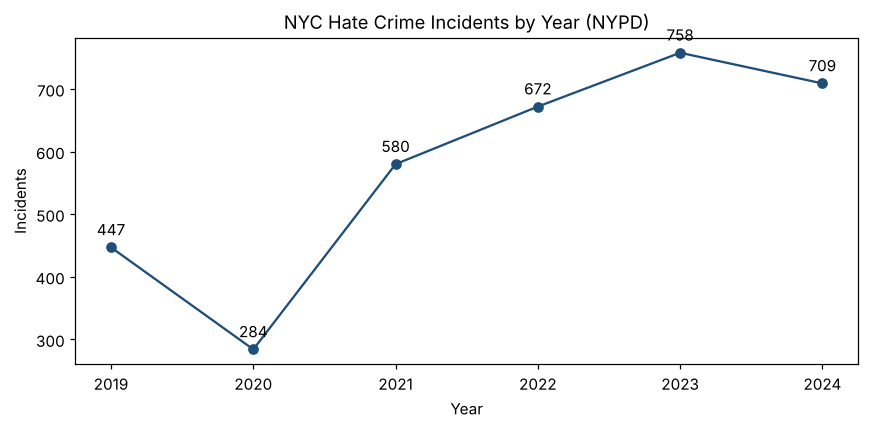

,Incidents
Year,
2019,447
2020,284
2021,580
2022,672
2023,758
2024,709


In [3]:
by_year = nypd["complaint_year_number"].value_counts().sort_index()
by_year.index.name = "Year"
by_year.name = "Incidents"

ax = by_year.plot(kind="line", marker="o", color="#1f4e79", figsize=(8, 4))
ax.set_title("NYC Hate Crime Incidents by Year (NYPD)")
ax.set_xlabel("Year"); ax.set_ylabel("Incidents")
for x, y in by_year.items():
    ax.annotate(str(y), (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
plt.tight_layout(); plt.show()

by_year.to_frame()

## 3. Hate crimes by NYPD patrol borough (Figure 2)

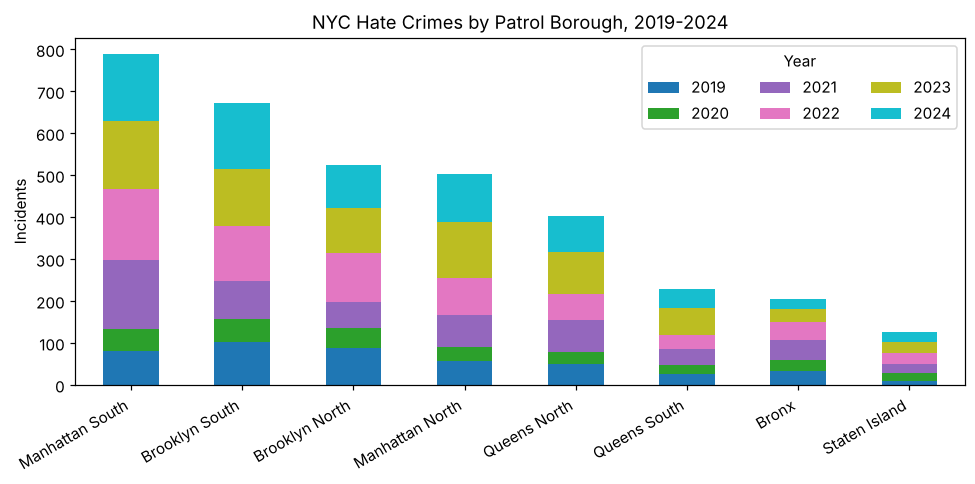

,2019,2020,2021,2022,2023,2024,Total
region,,,,,,,
Manhattan South,82,52,165,168,162,159,788
Brooklyn South,103,55,90,131,136,157,672
Brooklyn North,87,50,62,116,108,101,524
Manhattan North,56,34,78,88,133,115,504
Queens North,51,27,77,63,99,85,402
Queens South,25,22,38,35,64,44,228
Bronx,33,26,49,43,30,24,205
Staten Island,10,18,21,28,26,24,127


In [4]:
region_names = {
    "BKLYN NORTH": "Brooklyn North", "BKLYN SOUTH": "Brooklyn South", "BRONX": "Bronx",
    "MAN NORTH": "Manhattan North", "MAN SOUTH": "Manhattan South",
    "QUEENS NORTH": "Queens North", "QUEENS SOUTH": "Queens South", "STATEN ISLAND": "Staten Island",
}
by_region = (nypd.assign(region=nypd["patrol_borough_name"].map(region_names))
                 .groupby(["region", "complaint_year_number"]).size()
                 .unstack("complaint_year_number"))
by_region.columns.name = None
by_region["Total"] = by_region.sum(axis=1)
by_region = by_region.sort_values("Total", ascending=False)

by_region.drop(columns="Total").plot(kind="bar", stacked=True, figsize=(9, 4.5), colormap="tab10")
plt.title("NYC Hate Crimes by Patrol Borough, 2019-2024")
plt.ylabel("Incidents"); plt.xlabel("")
plt.xticks(rotation=30, ha="right"); plt.legend(title="Year", ncol=3)
plt.tight_layout(); plt.show()

by_region

## 4. NEW: Hate crimes per 100,000 residents by borough
Raw counts favor large boroughs. Dividing by population shows how often hate crimes occur relative to the number of people who live there. Populations are from the 2020 U.S. Census.

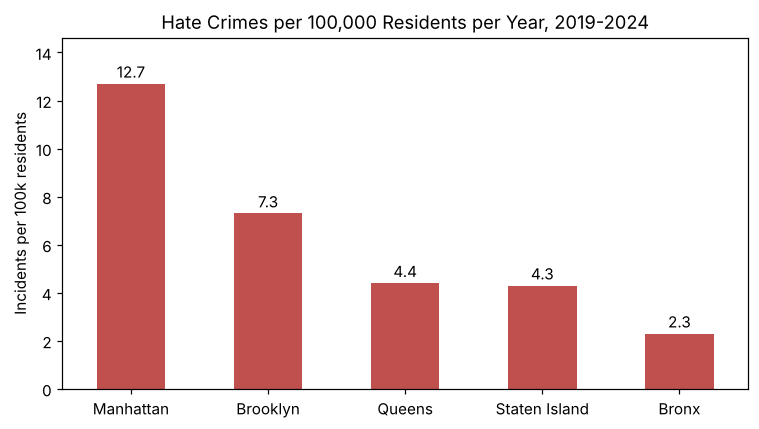

,incidents,population_2020,per_100k_total,per_100k_per_year
borough,,,,
Manhattan,1292,1694251,76.3,12.7
Brooklyn,1196,2736074,43.7,7.3
Queens,630,2405464,26.2,4.4
Staten Island,127,495747,25.6,4.3
Bronx,205,1472654,13.9,2.3


In [5]:
census_2020 = {
    "NEW YORK": ("Manhattan", 1694251),
    "KINGS": ("Brooklyn", 2736074),
    "QUEENS": ("Queens", 2405464),
    "BRONX": ("Bronx", 1472654),
    "RICHMOND": ("Staten Island", 495747),
}
years = nypd["complaint_year_number"].nunique()

per_capita = nypd["county"].value_counts().rename("incidents").to_frame()
per_capita["borough"] = [census_2020[c][0] for c in per_capita.index]
per_capita["population_2020"] = [census_2020[c][1] for c in per_capita.index]
per_capita["per_100k_total"] = per_capita["incidents"] / per_capita["population_2020"] * 100_000
per_capita["per_100k_per_year"] = per_capita["per_100k_total"] / years
per_capita = per_capita.set_index("borough").sort_values("per_100k_per_year", ascending=False).round(1)

ax = per_capita["per_100k_per_year"].plot(kind="bar", color="#c0504d", figsize=(7, 4))
ax.set_title("Hate Crimes per 100,000 Residents per Year, 2019-2024")
ax.set_ylabel("Incidents per 100k residents"); ax.set_xlabel("")
for i, v in enumerate(per_capita["per_100k_per_year"]):
    ax.annotate(f"{v}", (i, v), textcoords="offset points", xytext=(0, 4), ha="center")
ax.set_ylim(0, per_capita["per_100k_per_year"].max() * 1.15)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

per_capita

## 5. Bias motivation (Figure 3)

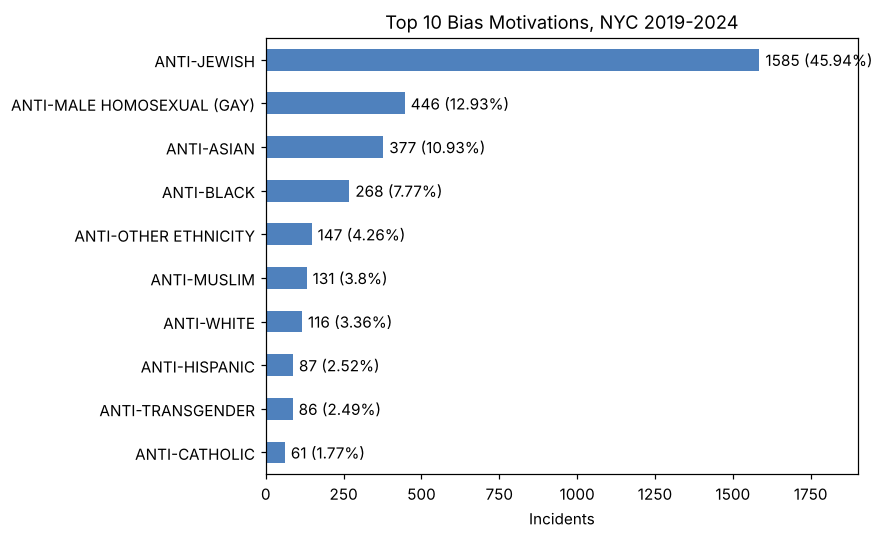

,incidents,percent
bias_motive_description,,
ANTI-JEWISH,1585,45.94
ANTI-MALE HOMOSEXUAL (GAY),446,12.93
ANTI-ASIAN,377,10.93
ANTI-BLACK,268,7.77
ANTI-OTHER ETHNICITY,147,4.26
ANTI-MUSLIM,131,3.80
ANTI-WHITE,116,3.36
ANTI-HISPANIC,87,2.52
ANTI-TRANSGENDER,86,2.49


In [6]:
motive = nypd["bias_motive_description"].value_counts().rename("incidents").to_frame()
motive["percent"] = (motive["incidents"] / motive["incidents"].sum() * 100).round(2)

top10 = motive.head(10).iloc[::-1]
ax = top10["incidents"].plot(kind="barh", color="#4f81bd", figsize=(8, 5))
ax.set_title("Top 10 Bias Motivations, NYC 2019-2024")
ax.set_xlabel("Incidents"); ax.set_ylabel("")
for i, (n, p) in enumerate(zip(top10["incidents"], top10["percent"])):
    ax.annotate(f"{n} ({p}%)", (n, i), textcoords="offset points", xytext=(4, -4))
plt.xlim(0, motive["incidents"].max() * 1.2); plt.tight_layout(); plt.show()

motive.head(10)

## 6. Year-over-year change: all hate crimes vs. anti-Jewish (Table 2)

In [7]:
anti_jewish = (nypd[nypd["bias_motive_description"] == "ANTI-JEWISH"]["complaint_year_number"]
               .value_counts().sort_index())

yoy = pd.DataFrame({
    "All incidents": by_year,
    "All: % change": (by_year.pct_change() * 100).round(2),
    "Anti-Jewish": anti_jewish,
    "Anti-Jewish: % change": (anti_jewish.pct_change() * 100).round(2),
})
yoy

,All incidents,All: % change,Anti-Jewish,Anti-Jewish: % change
2019,447,NaN,252,NaN
2020,284,-36.47,126,-50.00
2021,580,104.23,215,70.63
2022,672,15.86,279,29.77
2023,758,12.80,343,22.94
2024,709,-6.46,370,7.87


## 7. Bias motivation trends over time (Figure 4)

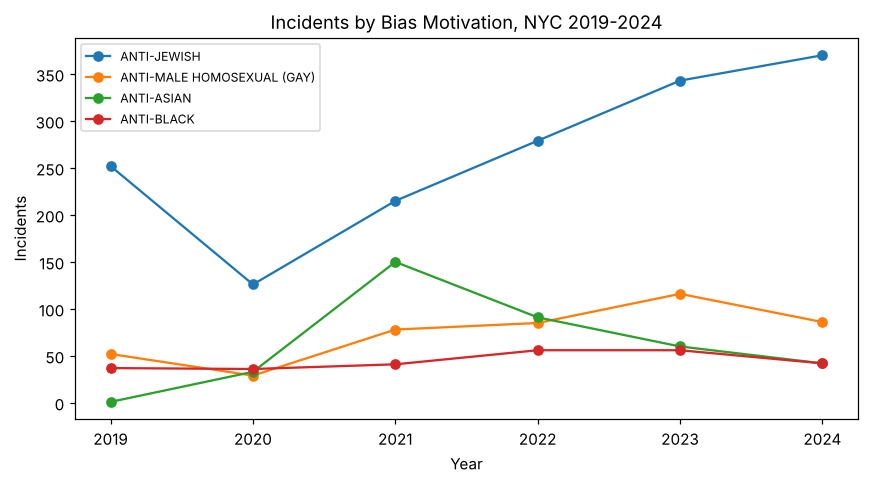

,ANTI-JEWISH,ANTI-MALE HOMOSEXUAL (GAY),ANTI-ASIAN,ANTI-BLACK
complaint_year_number,,,,
2019,252,52,1,37
2020,126,29,33,36
2021,215,78,150,41
2022,279,85,91,56
2023,343,116,60,56
2024,370,86,42,42


In [8]:
main_groups = ["ANTI-JEWISH", "ANTI-MALE HOMOSEXUAL (GAY)", "ANTI-ASIAN", "ANTI-BLACK"]
trend = (nypd[nypd["bias_motive_description"].isin(main_groups)]
         .groupby(["complaint_year_number", "bias_motive_description"]).size()
         .unstack("bias_motive_description")[main_groups])
trend.columns.name = None

trend.plot(marker="o", figsize=(8, 4.5))
plt.title("Incidents by Bias Motivation, NYC 2019-2024")
plt.xlabel("Year"); plt.ylabel("Incidents"); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

trend

## 8. NYC vs. the rest of New York State (Figure 1)
DCJS county data covers 2010–2022. For 2023, DCJS's regional update gives the rest-of-state total but not NYC's, so NYC's 2023 figure comes from the NYPD data.

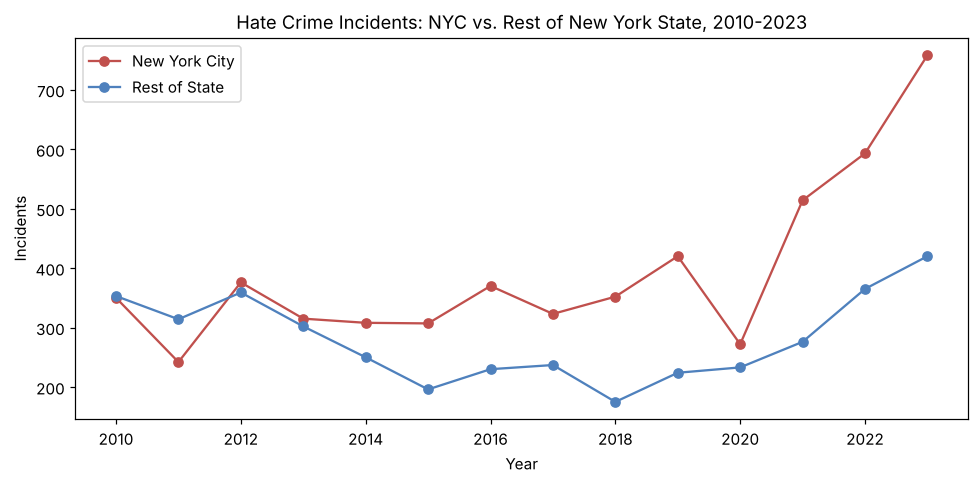

,New York City,Rest of State
year,,
2018,352,175
2019,420,224
2020,272,233
2021,514,276
2022,593,365
2023,758,420


In [9]:
county = pd.read_csv(os.path.join(DATA_DIR, "hatecrime_by_county.csv"))
nyc_counties = ["Bronx", "Kings", "New York", "Queens", "Richmond"]

state_trend = pd.DataFrame({
    "New York City": county[county["county"].isin(nyc_counties)].groupby("year")["total_incidents"].sum(),
    "Rest of State": county[~county["county"].isin(nyc_counties)].groupby("year")["total_incidents"].sum(),
})

# 2023: rest of state from the DCJS 2023 update (row 5, last column), NYC from NYPD
dcjs_2023 = pd.read_excel(os.path.join(DATA_DIR, "hate_crime_bias_type_2023.xlsx"), header=None)
rest_of_state_2023 = int(dcjs_2023.iloc[5, 16])
state_trend.loc[2023] = [by_year[2023], rest_of_state_2023]
state_trend = state_trend.astype(int)

state_trend.plot(marker="o", figsize=(9, 4.5), color=["#c0504d", "#4f81bd"])
plt.title("Hate Crime Incidents: NYC vs. Rest of New York State, 2010-2023")
plt.xlabel("Year"); plt.ylabel("Incidents")
plt.tight_layout(); plt.show()

state_trend.tail(6)

## 9. Federal vs. state/city counts (Table 3)
Compares the U.S. Department of Justice total for New York State with the sum of the NYC and rest-of-state figures above.

In [10]:
# DOJ values as published at https://www.justice.gov/hatecrimes/state-data/new-york (accessed May 2025)
federal = pd.Series({2022: 953, 2023: 1048}, name="Federal (DOJ)")

comparison = pd.DataFrame({
    "Federal (DOJ)": federal,
    "NY State + NYPD": state_trend.loc[[2022, 2023]].sum(axis=1),
})
comparison["Difference"] = comparison["NY State + NYPD"] - comparison["Federal (DOJ)"]
comparison

,Federal (DOJ),NY State + NYPD,Difference
2022,953,958,5
2023,1048,1178,130


## 10. Offender race, NYPD reports to the FBI (Figure 5)
From the FBI's NIBRS hate crime file, filtered to the NYPD. This file runs through 2023.

NYPD hate crime incidents reported to the FBI, 2019-2023: 2373


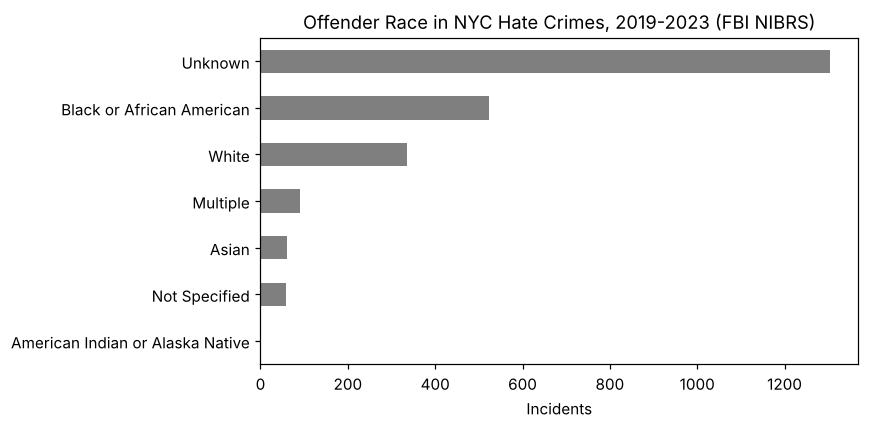

,incidents,percent
offender_race,,
Unknown,1303,54.9
Black or African American,523,22.0
White,336,14.2
Multiple,90,3.8
Asian,61,2.6
Not Specified,58,2.4
American Indian or Alaska Native,2,0.1


In [11]:
nibrs = pd.read_csv(os.path.join(DATA_DIR, "nibrs_nyc_hate_crime_2019_2023.csv"))
print("NYPD hate crime incidents reported to the FBI, 2019-2023:", len(nibrs))

offender = nibrs["offender_race"].value_counts().rename("incidents").to_frame()
offender["percent"] = (offender["incidents"] / offender["incidents"].sum() * 100).round(1)

ax = offender["incidents"].iloc[::-1].plot(kind="barh", color="#7f7f7f", figsize=(8, 4))
ax.set_title("Offender Race in NYC Hate Crimes, 2019-2023 (FBI NIBRS)")
ax.set_xlabel("Incidents"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

offender

## 11. NEW: Where hate crimes happen
The same FBI file records the location type of each incident.

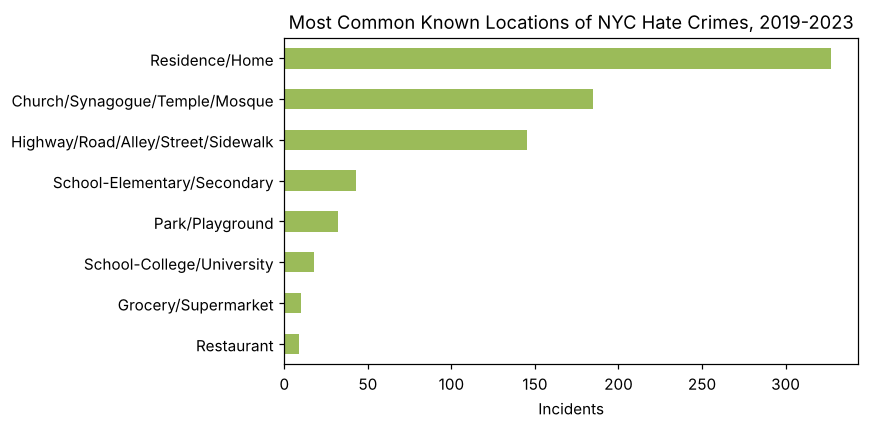

,incidents,percent
location_name,,
Other/Unknown,1560,65.7
Residence/Home,327,13.8
Church/Synagogue/Temple/Mosque,185,7.8
Highway/Road/Alley/Street/Sidewalk,145,6.1
School-Elementary/Secondary,43,1.8
Park/Playground,32,1.3
School-College/University,18,0.8
Grocery/Supermarket,10,0.4


In [12]:
locations = nibrs["location_name"].value_counts().rename("incidents").to_frame()
locations["percent"] = (locations["incidents"] / locations["incidents"].sum() * 100).round(1)

known = locations.drop(index="Other/Unknown").head(8).iloc[::-1]
ax = known["incidents"].plot(kind="barh", color="#9bbb59", figsize=(8, 4))
ax.set_title("Most Common Known Locations of NYC Hate Crimes, 2019-2023")
ax.set_xlabel("Incidents"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

locations.head(8)

## Key findings
- Hate crimes fell from 447 in 2019 to 284 in 2020, then rose to a peak of 758 in 2023 before dipping to 709 in 2024.
- **Anti-Jewish** incidents make up 45.9% of all cases (1,585) and rose every year from 2020 to 2024, even when the total fell in 2024.
- **Anti-Asian** incidents spiked in 2021 (150) while the total also more than doubled, then declined.
- **Per resident, Manhattan has the highest rate by far** (12.7 per 100k per year), about 5.5 times the Bronx (2.3). Manhattan's large commuter and tourist population likely contributes. Staten Island, lowest in raw counts, has about the same rate as Queens.
- 55% of NYPD-reported incidents list the offender's race as "Unknown," and 66% list the location as "Other/Unknown," which limits analysis of who commits these crimes and where.
- Among known locations, **homes** and **places of worship** are the most common.

## Limitations
- Counts reflect reported and confirmed hate crimes only; underreporting is likely.
- Federal, state, and city figures differ because of different definitions and reporting systems.
- Timing alone can't show what *caused* changes in a bias category; events like COVID-19 and conflict in the Middle East coincide with shifts but aren't tested directly.
- Per-resident rates use where people live, not where they spend their day.